## 실습 풀이: 이상거래 탐지 모델 비교

정상 거래의 패턴으로 이상 점수를 계산하고, 실제 사기 라벨로 탐지 성능을 평가한다.
사기를 찾아낸 건수와 정상 거래를 이상거래로 예측한 건수를 함께 고려한다.


In [1]:
from copy import deepcopy
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42


### 데이터 준비

ULB 카드 거래 데이터는 한 행이 거래 한 건이며, `Class`는 정상 0·사기 1이다.
`V1`~`V28`은 PCA로 변환된 익명 수치 특성이고, `Amount`는 거래 금액이다.
결측값과 원본 열의 값이 모두 같은 중복 행의 수를 확인한다.


In [2]:
data_path = Path("data/creditcard.csv")
if not data_path.exists():
    # parents=True: 상위 폴더도 생성, exist_ok=True: 기존 폴더를 허용한다.
    data_path.parent.mkdir(parents=True, exist_ok=True)
    url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
    # urlretrieve: URL의 파일을 지정한 로컬 경로에 저장한다.
    urlretrieve(url, data_path)

raw_transactions = pd.read_csv(data_path)
# arange: 0부터 행 수 - 1까지 생성. insert: 원본 행 번호를 첫 열에 추가한다.
raw_transactions.insert(0, "record_id", np.arange(len(raw_transactions)))

display(raw_transactions.head())

# 행마다 다른 record_id를 제외한 원본 열로 중복을 비교한다.
original_columns = raw_transactions.columns.drop("record_id").tolist()
# isna: 결측 여부를 표시. 두 번의 sum으로 모든 열의 결측값 수를 합친다.
print("결측값 수:", int(raw_transactions[original_columns].isna().sum().sum()))

# duplicated: 첫 행 이후 같은 값이 반복된 행을 True로 표시한다.
duplicate_mask = raw_transactions.duplicated(subset=original_columns)
print("중복 행 수:", int(duplicate_mask.sum()))


,record_id,Time,V1,V2,V3,V4,V5,V6,V7,V8,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


결측값 수: 0
중복 행 수: 1081


### 중복 제거

동일한 관측값이 학습·평가 집합에 함께 들어가는 것을 막기 위해 중복 행은 첫 행만 남긴다.


In [3]:
# subset: 중복을 비교할 열, keep="first": 첫 번째 행을 남긴다.
transactions = raw_transactions.drop_duplicates(
    subset=original_columns,
    keep="first",
).copy()

print("제거한 중복 행:", len(raw_transactions) - len(transactions))
print("사용할 거래 수:", len(transactions))
display(transactions["Class"].value_counts().rename("transactions"))

# Class가 0·1이므로 평균은 사기 거래의 비율이다.
fraud_rate = transactions["Class"].mean()
print(f"사기 비율: {fraud_rate:.3%}")


제거한 중복 행: 1081
사용할 거래 수: 283726


Class
0    283253
1       473
Name: transactions, dtype: int64

사기 비율: 0.167%


### 데이터 분리와 모델 입력

사기 비율을 유지하며 학습 64%·검증 16%·테스트 20%로 분리한다.
모델은 정상 학습 거래로 학습하고, 검증 거래의 정상·사기 라벨로 설정과 임계값을 선택한다. 테스트는 선택이 끝난 모델을 평가하는 데 사용한다.

모든 실험에서 같은 분할과 `V1`~`V28`, `log1p(Amount)` 입력을 사용한다. `Time`·`Class`·`record_id`는 모델 입력에서 제외한다.


In [4]:
# train_test_split: 입력과 같은 열을 가진 두 DataFrame을 반환한다.
train, test = train_test_split(
    transactions,
    test_size=0.2,  # 두 번째 집합의 비율
    stratify=transactions["Class"],  # 클래스 비율을 유지한다.
    random_state=SEED,  # 같은 무작위 분할을 재현한다.
)
train, validation = train_test_split(
    train,
    test_size=0.2,
    stratify=train["Class"],
    random_state=SEED,
)

parts = {"train": train, "validation": validation, "test": test}
display(pd.DataFrame([
    {
        "split": name,
        "transactions": len(frame),
        "fraud": int(frame["Class"].sum()),
        "fraud_rate": frame["Class"].mean(),
    }
    for name, frame in parts.items()
]))

FEATURE_COLUMNS = [f"V{i}" for i in range(1, 29)]


def make_features(frame, feature_columns):
    # 거래 DataFrame을 받아 같은 행 순서의 (거래 수, 29) DataFrame을 반환한다.
    features = frame[feature_columns].copy()
    # log1p: 각 금액 x에 log(1 + x)를 적용하며, 0은 0으로 변환한다.
    features["log_amount"] = np.log1p(frame["Amount"])
    return features


train_features = make_features(train, FEATURE_COLUMNS)
validation_features = make_features(validation, FEATURE_COLUMNS)
test_features = make_features(test, FEATURE_COLUMNS)

# to_numpy: 라벨 열을 (거래 수,) 모양의 배열로 바꾼다.
y_train = train["Class"].to_numpy()
y_val = validation["Class"].to_numpy()
y_test = test["Class"].to_numpy()

# 입력과 라벨의 행 순서가 같으므로 정상 라벨에 해당하는 입력 행을 고른다.
normal_train_features = train_features.loc[y_train == 0]
print(
    "학습·검증·테스트 입력 모양:",
    train_features.shape,
    validation_features.shape,
    test_features.shape,
)
display(train_features.head())


,split,transactions,fraud,fraud_rate
0,train,181584,302,0.001663
1,validation,45396,76,0.001674
2,test,56746,95,0.001674


학습·검증·테스트 입력 모양: (181584, 29) (45396, 29) (56746, 29)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,log_amount
135251,-4.668495,3.932560,-0.343116,-2.199315,-1.041493,-0.859191,0.119151,0.567686,2.825739,4.016222,...,1.893346,-0.465558,-0.320141,0.194736,0.057258,0.352072,0.736281,0.991712,0.513882,1.495149
112506,-1.193228,-0.067069,0.195100,-0.797864,-2.724207,2.082131,2.237805,0.279369,0.186022,-1.367085,...,-0.071902,-0.077393,-0.077975,0.425741,-0.743803,-0.710705,0.689694,0.110856,-0.047984,6.422289
129491,-2.139337,-0.477542,1.023329,0.553691,-0.760199,-0.079801,-0.250863,0.230727,-0.971462,0.726832,...,-0.937935,-0.350356,0.261436,0.228479,-0.074661,0.097454,-0.133517,0.282959,-0.037037,4.791650
220399,1.473130,-0.771461,-1.935011,1.648650,0.002056,-1.161882,0.969145,-0.457524,0.339598,0.164073,...,0.225142,0.208218,0.105906,-0.250718,0.035859,0.326683,-0.522441,-0.080269,-0.013062,5.707110
86546,0.874556,0.028103,0.949206,2.427185,-0.346842,0.522520,-0.251504,0.242281,-0.755448,0.743199,...,0.063057,0.257700,0.494448,-0.117962,0.021798,0.276067,0.069338,0.006406,0.035184,4.709170


### 오토인코더 입력 표준화

오토인코더는 특성별 크기 차이가 복원 오차에 미치는 영향을 줄이도록 표준화한 값을 사용한다.
정상 학습 거래에서 구한 평균과 표준편차를 검증·테스트에도 적용한다. Isolation Forest에는 표준화 전 입력을 사용한다.


In [5]:
ae_scaler = StandardScaler()
# fit_transform: 정상 학습 거래로 통계를 구하고 변환한다.
X_ae_train = ae_scaler.fit_transform(normal_train_features).astype("float32")
X_ae_val = ae_scaler.transform(validation_features).astype("float32")
X_ae_test = ae_scaler.transform(test_features).astype("float32")

# 학습 중 복원 품질은 검증 집합의 정상 거래로 확인한다.
X_ae_val_normal = X_ae_val[y_val == 0]
print("정상 학습 입력:", X_ae_train.shape)
print("정상 검증 입력:", X_ae_val_normal.shape)
display(pd.DataFrame(
    X_ae_train[:5],
    columns=train_features.columns,
))


정상 학습 입력: (181282, 29)
정상 검증 입력: (45320, 29)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,log_amount
0,-2.432499,2.395924,-0.247406,-1.560784,-0.784705,-0.650506,0.094898,0.495823,2.598255,3.874733,...,2.479646,-0.651039,-0.443175,0.306699,0.096298,0.673818,1.527163,2.543883,1.562335,-1.004682
1,-0.625945,-0.033021,0.123353,-0.562187,-2.040515,1.575126,1.938225,0.244518,0.168311,-1.328345,...,-0.093411,-0.109908,-0.108358,0.672112,-1.224499,-1.362915,1.430443,0.281351,-0.147135,1.972228
2,-1.117762,-0.282298,0.693891,0.400857,-0.574775,-0.060759,-0.227031,0.202121,-0.897190,0.695469,...,-1.227289,-0.490439,0.360909,0.360075,-0.121211,0.185860,-0.278660,0.723408,-0.113829,0.987018
3,0.760113,-0.460792,-1.344009,1.181064,-0.005903,-0.879545,0.834432,-0.397777,0.309682,0.151551,...,0.295503,0.288255,0.145875,-0.397937,0.061014,0.625160,-1.086121,-0.209565,-0.040883,1.540127
4,0.448956,0.024776,0.642831,1.735806,-0.266286,0.395004,-0.227588,0.212192,-0.698342,0.711288,...,0.083288,0.357237,0.683069,-0.187939,0.037831,0.528159,0.142495,0.013064,0.105903,0.937185


### 비교 기준

이상 점수가 임계값 이상이면 이상거래로 예측한다.
검증 F1로 모델과 임계값의 조합을 비교하며, AP·정밀도·재현율·오탐(FP)·미탐(FN)·이상거래 예측 건수를 함께 확인한다.
AP는 여러 임계값에서의 정밀도를 재현율 증가량으로 가중 평균한 값이며, 선택한 임계값과 무관하다.


In [6]:
def detection_metrics(actual, scores, threshold):
    # actual과 scores: 같은 거래 순서의 (거래 수,) 라벨과 연속 점수.
    # asarray로 점수를 배열로 바꾸고, 임계값 이상인 거래를 True로 표시한다.
    predicted = np.asarray(scores) >= threshold

    # labels=[0, 1]인 2×2 혼동 행렬을 펼치면 TN, FP, FN, TP 순서다.
    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1],
    ).ravel()

    # zero_division=0: 분모가 0인 정밀도·재현율·F1을 0으로 처리한다.
    return {
        "AP": average_precision_score(actual, scores),
        "ROC_AUC": roc_auc_score(actual, scores),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1": f1_score(actual, predicted, zero_division=0),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "predicted_count": int(predicted.sum()),  # True인 거래 수를 합산한다.
    }


## Isolation Forest의 학습 조건 비교

기준 설정에서 한 항목씩 바꿔 트리가 사용하는 거래와 특성, 트리 수의 영향을 비교한다.

| 실험 | 트리 수 | 트리별 거래 수 | 트리별 특성 비율 |
| --- | --- | --- | --- |
| `IF_100` | 100 | 256 | 1.0 |
| `IF_300` | 300 | 256 | 1.0 |
| `IF_samples_1024` | 100 | 1,024 | 1.0 |
| `IF_features_0.5` | 100 | 256 | 0.5 |

트리 수를 늘리면 더 많은 무작위 분할 결과를 종합한다. 트리별 거래 수와 특성 비율을 바꾸면 각 트리가 학습에 사용하는 데이터가 달라진다.
모든 설정에서 임계값 0.45·0.50·0.55·0.60·0.65·0.70을 비교한다.


In [7]:
IF_BASE = {"n_estimators": 100, "max_samples": 256, "max_features": 1.0}
IF_CHANGES = {
    "IF_100": {},
    "IF_300": {"n_estimators": 300},
    "IF_samples_1024": {"max_samples": 1024},
    "IF_features_0.5": {"max_features": 0.5},
}
# 기준값과 변경값을 합쳐 설정별로 독립적인 딕셔너리를 만든다.
IF_SETTINGS = {name: {**IF_BASE, **changes} for name, changes in IF_CHANGES.items()}
THRESHOLDS = [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
models = {}
validation_scores = {}
forest_rows = []

for name, settings in IF_SETTINGS.items():
    model = IsolationForest(
        # n_estimators: 트리 수, max_samples: 트리별 거래 수,
        # max_features: 실수이면 트리별로 사용할 특성의 비율.
        **settings,
        random_state=SEED,
        n_jobs=-1,
    )
    model.fit(normal_train_features)
    # score_samples는 낮을수록 이상이므로 부호를 바꾼다. 모양은 (검증 거래 수,)다.
    scores = -model.score_samples(validation_features)
    models[name] = model
    validation_scores[name] = scores
    for threshold in THRESHOLDS:
        forest_rows.append({
            "model": name,
            "threshold": threshold,
            **detection_metrics(y_val, scores, threshold),
        })

forest_results = pd.DataFrame(forest_rows)
display(forest_results.round(4))


,model,threshold,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
0,IF_100,0.45,0.1880,0.9461,0.0140,0.8947,0.0276,68,4775,8,4843
1,IF_100,0.50,0.1880,0.9461,0.0406,0.8816,0.0776,67,1583,9,1650
2,IF_100,0.55,0.1880,0.9461,0.0846,0.8158,0.1533,62,671,14,733
3,IF_100,0.60,0.1880,0.9461,0.1264,0.4605,0.1983,35,242,41,277
4,IF_100,0.65,0.1880,0.9461,0.1860,0.2105,0.1975,16,70,60,86
5,IF_100,0.70,0.1880,0.9461,0.3333,0.0789,0.1277,6,12,70,18
6,IF_300,0.45,0.2096,0.9457,0.0135,0.9079,0.0265,69,5055,7,5124
7,IF_300,0.50,0.2096,0.9457,0.0395,0.8816,0.0755,67,1631,9,1698
8,IF_300,0.55,0.2096,0.9457,0.0808,0.8026,0.1468,61,694,15,755
9,IF_300,0.60,0.2096,0.9457,0.1352,0.5658,0.2183,43,275,33,318


## 오토인코더의 구조와 학습 조건 비교

오토인코더는 정상 입력을 압축한 뒤 복원하도록 학습한다. 거래별 복원 MSE를 이상 점수로 사용한다.
`TransactionAutoencoder`는 `29 → 은닉층 너비 → 잠재 차원 → 은닉층 너비 → 29` 구조다.
은닉층 너비는 압축·복원 과정에서 계산하는 값의 개수이고, 잠재 차원은 압축된 표현의 크기다.
마지막 층은 표준화된 입력의 음수·양수를 모두 복원하도록 선형 출력을 사용한다.


In [8]:
# CPU에서 실행하며, 작은 신경망의 연산에 사용할 스레드 수를 정한다.
torch.set_num_threads(2)


class TransactionAutoencoder(nn.Module):
    def __init__(self, input_dim=29, latent_dim=4, hidden_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),  # 입력 특성 수 → 출력 특성 수
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, inputs):
        # 입력과 복원값의 모양은 모두 (배치 거래 수, 29)다.
        return self.decoder(self.encoder(inputs))


### 학습과 가중치 선택

정상 검증 MSE가 가장 작은 에포크의 가중치를 사용한다.
각 실험은 모델·옵티마이저·배치 생성기를 새로 만들고 같은 난수 시드에서 시작한다. 옵티마이저는 Adam으로 유지한다.


In [9]:
def fit_autoencoder(latent_dim, epochs, lr=0.001, batch_size=512, hidden_dim=16):
    # manual_seed: 가중치 초기화와 학습 순서의 난수 시드를 고정한다.
    torch.manual_seed(SEED)
    model = TransactionAutoencoder(X_ae_train.shape[1], latent_dim, hidden_dim)

    # from_numpy: 배열을 텐서로 변환. TensorDataset: 거래별로 꺼낼 데이터셋.
    dataset = TensorDataset(torch.from_numpy(X_ae_train))
    loader = DataLoader(
        dataset,
        batch_size=batch_size,  # 한 번에 학습할 거래 수
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    validation_tensor = torch.from_numpy(X_ae_val_normal)
    # parameters(): 학습할 가중치, lr: 가중치 갱신 크기를 조절하는 학습률.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_function = nn.MSELoss()  # 배치의 거래·특성 전체에 대한 평균 제곱 오차
    best_loss = float("inf")
    best_state = None
    rows = []

    for epoch in range(epochs):
        model.train()  # 학습 모드
        total_loss = 0.0

        for (inputs,) in loader:
            optimizer.zero_grad()  # 이전 배치의 기울기를 비운다.
            restored = model(inputs)
            loss = loss_function(restored, inputs)
            loss.backward()  # 가중치별 손실의 기울기를 계산한다.
            optimizer.step()  # 계산한 기울기로 가중치를 갱신한다.
            # item(): 손실 텐서를 숫자로 꺼낸다. 거래 수로 가중해 합산한다.
            total_loss += loss.item() * len(inputs)

        model.eval()  # 평가 모드
        with torch.no_grad():  # 평가에는 기울기를 기록하지 않는다.
            validation_loss = loss_function(
                model(validation_tensor),
                validation_tensor,
            ).item()

        if validation_loss < best_loss:
            best_loss = validation_loss
            # state_dict: 가중치 묶음. 이후 학습과 분리해 복사한다.
            best_state = deepcopy(model.state_dict())

        rows.append({
            "epoch": epoch + 1,
            "train_MSE": total_loss / len(X_ae_train),
            "normal_val_MSE": validation_loss,
        })

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(rows)


In [10]:
@torch.no_grad()  # 함수 전체에서 기울기 기록을 끈다.
def reconstruction_scores(model, values):
    model.eval()
    restored = model(torch.from_numpy(values)).numpy()
    # axis=1: 각 행의 29개 특성 오차를 평균해 (거래 수,) 점수를 만든다.
    scores = ((values - restored) ** 2).mean(axis=1)
    return restored, scores  # (거래 수, 29) 복원값, (거래 수,) 점수


### 변경 조건

기준 설정은 잠재 차원 4, 20에포크, 학습률 0.001, 배치 크기 512, 은닉층 너비 16이다.
한 항목씩 바꿔 구조와 학습 조건의 영향을 비교한다.

| 실험 | 변경 항목 | 기준값 → 변경값 |
| --- | --- | --- |
| `AE_4_20` | 기준 설정 | 변경 없음 |
| `AE_12_20` | 잠재 차원 | 4 → 12 |
| `AE_4_40` | 학습 횟수 | 20 → 40에포크 |
| `AE_lr_0.0003` | 학습률 | 0.001 → 0.0003 |
| `AE_lr_0.003` | 학습률 | 0.001 → 0.003 |
| `AE_batch_128` | 배치 크기 | 512 → 128 |
| `AE_hidden_32` | 은닉층 너비 | 16 → 32 |

학습률은 한 번의 가중치 갱신 크기를 조절한다. 배치 크기는 한 번의 갱신에 사용할 거래 수이며, 같은 에포크 수에서 작은 배치는 더 많은 갱신을 수행한다.
정상 검증 MSE는 복원 품질을, 실제 사기 라벨로 계산한 지표는 탐지 성능을 평가한다.


In [11]:
AE_BASE = {"latent_dim": 4, "epochs": 20, "lr": 0.001, "batch_size": 512, "hidden_dim": 16}
AE_CHANGES = {
    "AE_4_20": {},
    "AE_12_20": {"latent_dim": 12},
    "AE_4_40": {"epochs": 40},
    "AE_lr_0.0003": {"lr": 0.0003},
    "AE_lr_0.003": {"lr": 0.003},
    "AE_batch_128": {"batch_size": 128},
    "AE_hidden_32": {"hidden_dim": 32},
}
AE_SETTINGS = {name: {**AE_BASE, **changes} for name, changes in AE_CHANGES.items()}
ae_histories = {}
training_rows = []

for name, settings in AE_SETTINGS.items():
    model, history = fit_autoencoder(**settings)
    models[name] = model
    ae_histories[name] = history
    _, validation_scores[name] = reconstruction_scores(model, X_ae_val)
    # idxmin: 정상 검증 MSE가 가장 작은 행의 인덱스.
    best = history.loc[history["normal_val_MSE"].idxmin()]
    training_rows.append({
        "model": name,
        **settings,
        "selected_epoch": int(best["epoch"]),
        "normal_val_MSE": best["normal_val_MSE"],
    })
    print(name, "학습 완료")

training_results = pd.DataFrame(training_rows)
display(training_results.round(4))


AE_4_20 학습 완료


AE_12_20 학습 완료


AE_4_40 학습 완료


AE_lr_0.0003 학습 완료


AE_lr_0.003 학습 완료


AE_batch_128 학습 완료


AE_hidden_32 학습 완료


,model,latent_dim,epochs,lr,batch_size,hidden_dim,selected_epoch,normal_val_MSE
0,AE_4_20,4,20,0.0010,512,16,20,0.5467
1,AE_12_20,12,20,0.0010,512,16,20,0.3976
2,AE_4_40,4,40,0.0010,512,16,40,0.5280
3,AE_lr_0.0003,4,20,0.0003,512,16,20,0.5945
4,AE_lr_0.003,4,20,0.0030,512,16,20,0.5147
5,AE_batch_128,4,20,0.0010,128,16,20,0.5182
6,AE_hidden_32,4,20,0.0010,512,32,20,0.4815


### 학습 곡선

가로축은 에포크, 세로축은 정상 거래의 복원 MSE다.
학습 횟수만 바꾼 두 실험은 같은 초기 상태와 배치 순서로 시작하므로 처음 20에포크의 곡선이 같다.


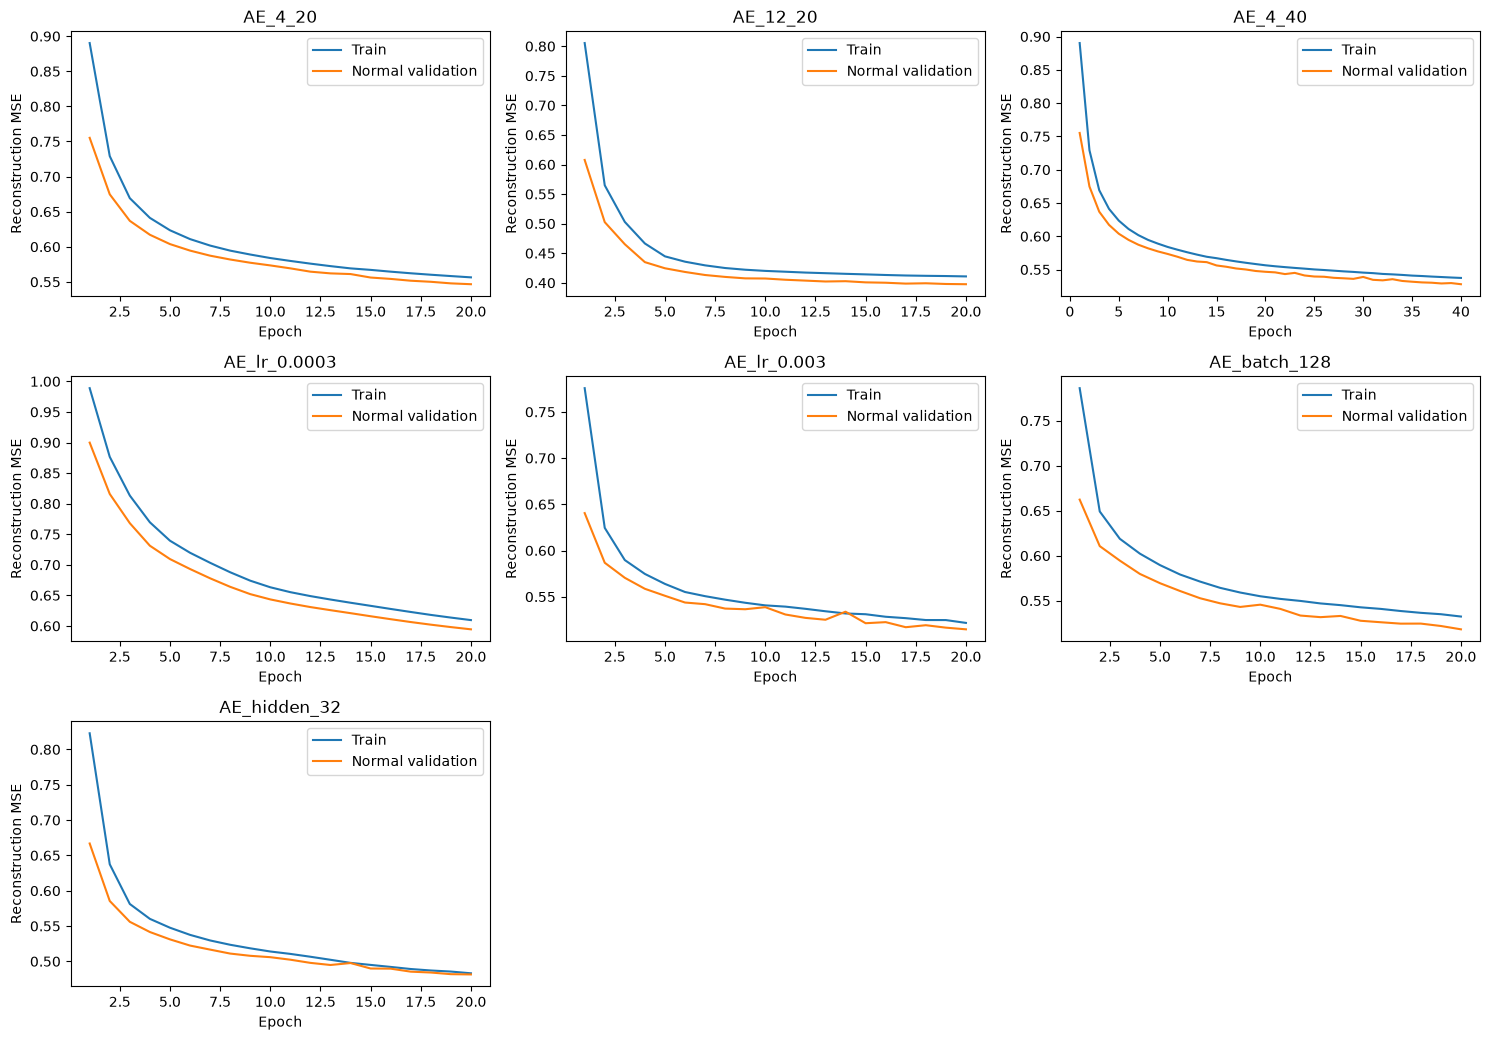

In [12]:
# 모델 수에 맞게 그래프 행 수를 정한다. squeeze=False는 axes를 2차원으로 유지한다.
columns = 3
rows = (len(AE_SETTINGS) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(15, 3.5 * rows), squeeze=False)
for ax, (name, history) in zip(axes.flat, ae_histories.items()):
    ax.plot(history["epoch"], history["train_MSE"], label="Train")
    ax.plot(history["epoch"], history["normal_val_MSE"], label="Normal validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Reconstruction MSE")
    ax.legend()
for ax in list(axes.flat)[len(AE_SETTINGS):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


### 복원 점수의 임계값 비교

정상 검증 거래의 복원 점수에서 95%·99%·99.5% 분위수를 구해 후보 임계값으로 비교한다.
99.5% 분위수는 정상 검증 거래의 약 99.5%가 그 이하의 점수를 갖는 값이다.
모든 오토인코더 설정에 같은 분위수 후보를 적용하고, 정상·사기를 포함한 전체 검증 거래로 평가한다.


In [13]:
AE_QUANTILES = [0.95, 0.99, 0.995]
ae_rows = []
for name in AE_SETTINGS:
    scores = validation_scores[name]
    for quantile in AE_QUANTILES:
        threshold = float(np.quantile(scores[y_val == 0], quantile))
        ae_rows.append({
            "model": name,
            "quantile": quantile,
            "threshold": threshold,
            **detection_metrics(y_val, scores, threshold),
        })

ae_results = pd.DataFrame(ae_rows)
display(ae_results.round(4))


,model,quantile,threshold,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
0,AE_4_20,0.950,1.1921,0.4527,0.9521,0.0283,0.8684,0.0548,66,2266,10,2332
1,AE_4_20,0.990,2.4552,0.4527,0.9521,0.1236,0.8421,0.2155,64,454,12,518
2,AE_4_20,0.995,3.7681,0.4527,0.9521,0.2172,0.8289,0.3443,63,227,13,290
3,AE_12_20,0.950,0.8625,0.3334,0.9473,0.0283,0.8684,0.0548,66,2266,10,2332
4,AE_12_20,0.990,2.5430,0.3334,0.9473,0.1236,0.8421,0.2155,64,454,12,518
5,AE_12_20,0.995,4.8946,0.3334,0.9473,0.1922,0.7105,0.3025,54,227,22,281
6,AE_4_40,0.950,1.1611,0.4487,0.9524,0.0287,0.8816,0.0556,67,2266,9,2333
7,AE_4_40,0.990,2.3431,0.4487,0.9524,0.1236,0.8421,0.2155,64,454,12,518
8,AE_4_40,0.995,3.5874,0.4487,0.9524,0.2199,0.8421,0.3488,64,227,12,291
9,AE_lr_0.0003,0.950,1.2514,0.3677,0.9393,0.0283,0.8684,0.0548,66,2266,10,2332


## 변경 전후 탐지 성능 비교

각 설정에서 검증 F1이 가장 높은 임계값을 선택한다. 동점이면 FP가 적고 임계값이 높은 후보를 고른다.
Isolation Forest는 `IF_100`, 오토인코더는 `AE_4_20`을 기준으로 변경한 설정의 결과를 비교한다.
모델 설정을 바꾸면 점수 분포도 달라지므로, 각 설정의 임계값을 같은 후보 기준에서 다시 선택한다.


In [14]:
# concat: 같은 이름의 열을 맞춰 후보별 결과를 한 표로 합친다.
all_results = pd.concat([forest_results, ae_results], ignore_index=True)
ordered = all_results.sort_values(
    ["f1", "FP", "threshold"], ascending=[False, True, False],
)
# 각 모델에서 우선순위가 가장 높은 행 하나를 남긴다.
best_per_model = ordered.drop_duplicates(subset="model", keep="first")
comparison = best_per_model.sort_values(
    ["f1", "FP", "model"], ascending=[False, True, True],
).reset_index(drop=True)
metric_columns = [
    "model", "threshold", "AP", "precision", "recall", "f1",
    "TP", "FP", "FN", "predicted_count",
]
display(comparison[metric_columns].round(4))


,model,threshold,AP,precision,recall,f1,TP,FP,FN,predicted_count
0,AE_4_40,3.5874,0.4487,0.2199,0.8421,0.3488,64,227,12,291
1,AE_hidden_32,3.2464,0.4915,0.2199,0.8421,0.3488,64,227,12,291
2,AE_lr_0.003,3.2012,0.4664,0.2199,0.8421,0.3488,64,227,12,291
3,AE_4_20,3.7681,0.4527,0.2172,0.8289,0.3443,63,227,13,290
4,AE_batch_128,4.3023,0.3880,0.2118,0.8026,0.3352,61,227,15,288
5,AE_lr_0.0003,4.6887,0.3677,0.2091,0.7895,0.3306,60,227,16,287
6,AE_12_20,4.8946,0.3334,0.1922,0.7105,0.3025,54,227,22,281
7,IF_300,0.6500,0.2096,0.2360,0.2763,0.2545,21,68,55,89
8,IF_samples_1024,0.6000,0.2301,0.1692,0.4474,0.2455,34,167,42,201
9,IF_features_0.5,0.7000,0.1722,0.4783,0.1447,0.2222,11,12,65,23


### 변경 결과 해석

Isolation Forest의 기준 설정은 AP 0.1880·F1 0.1983, 오토인코더의 기준 설정은 정상 검증 MSE 0.5467·AP 0.4527·F1 0.3443이다.
각 설정에서 선택된 임계값의 결과를 기준 설정과 비교한다.

| 바꾼 항목 | 실행 결과와 해석 |
| --- | --- |
| 트리 수 100 → 300 | AP 0.2096·F1 0.2545로 높아졌다. 선택 임계값도 0.60에서 0.65로 바뀌어, 탐지한 사기는 35건에서 21건으로 줄고 오탐은 242건에서 68건으로 줄었다. |
| 트리별 거래 수 256 → 1,024 | AP 0.2301·F1 0.2455로 높아졌다. 선택 임계값은 같은 0.60이며, 탐지한 사기는 35건에서 34건으로 줄고 오탐은 242건에서 167건으로 줄었다. |
| 트리별 특성 비율 1.0 → 0.5 | AP는 0.1722로 낮아지고 선택 조합의 F1은 0.2222로 높아졌다. 임계값 0.70에서 사기 11건을 탐지하고 오탐 12건을 냈다. 정밀도는 47.8%, 재현율은 14.5%로 많은 사기를 놓치는 설정이다. |
| 잠재 차원 4 → 12 | 정상 검증 MSE는 0.3976으로 줄고, AP는 0.3334·F1은 0.3025로 낮아졌다. 정상 거래의 복원 품질은 좋아졌고 사기 탐지 성능은 낮아졌다. |
| 학습 횟수 20 → 40 | 정상 검증 MSE는 0.5280으로 줄고 F1은 0.3488로 높아졌다. 오탐 227건을 유지하면서 사기를 한 건 더 탐지했다. AP는 0.4487로 조금 낮아졌다. |
| 학습률 0.001 → 0.0003 | 20에포크에서 정상 검증 MSE는 0.5945로 기준보다 높고, AP 0.3677·F1 0.3306으로 낮아졌다. 같은 학습 횟수에서 복원 품질과 탐지 성능 모두 기준보다 낮았다. |
| 학습률 0.001 → 0.003 | 정상 검증 MSE는 0.5147로 줄고, AP 0.4664·F1 0.3488로 높아졌다. 사기 64건을 탐지하고 오탐 227건을 냈다. |
| 배치 크기 512 → 128 | 정상 검증 MSE는 0.5182로 줄고, AP 0.3880·F1 0.3352로 낮아졌다. 같은 20에포크에서 가중치 갱신 횟수는 약 4배로 늘었다. |
| 은닉층 너비 16 → 32 | 정상 검증 MSE는 0.4815로 줄고, AP 0.4915·F1 0.3488로 높아졌다. AP는 비교한 설정 중 가장 높으며, 사기 64건을 탐지하고 오탐 227건을 냈다. |

모델 설정과 선택 임계값이 함께 달라지는 비교이므로 AP와 임계값별 탐지 건수를 함께 읽는다. 예를 들어 같은 임계값 0.60에서 트리를 100개에서 300개로 늘리면 탐지한 사기는 35건에서 43건으로, 오탐은 242건에서 275건으로 늘어난다.

오토인코더는 선택된 99.5% 분위수에서 정상 검증 거래의 오탐이 모두 227건이다. 이 조건에서 탐지한 사기의 수가 F1 차이로 이어진다. 기준 설정과 최고 F1의 차이는 검증 사기 한 건의 추가 탐지에서 나온 결과다.


### 정상·사기의 점수 분포

모델별로 선택한 임계값과 정상·사기 점수의 겹치는 구간을 확인한다.
큰 점수 사이의 간격을 줄이도록 가로축에 `log1p`를 적용하고 임계값도 같은 방식으로 변환한다. 세로축은 거래 수의 로그 척도다.
이상거래 여부와 평가 지표는 변환 전 점수로 계산한다. 모델별 점수의 척도가 달라 각 그래프 안에서 두 집단을 비교한다.


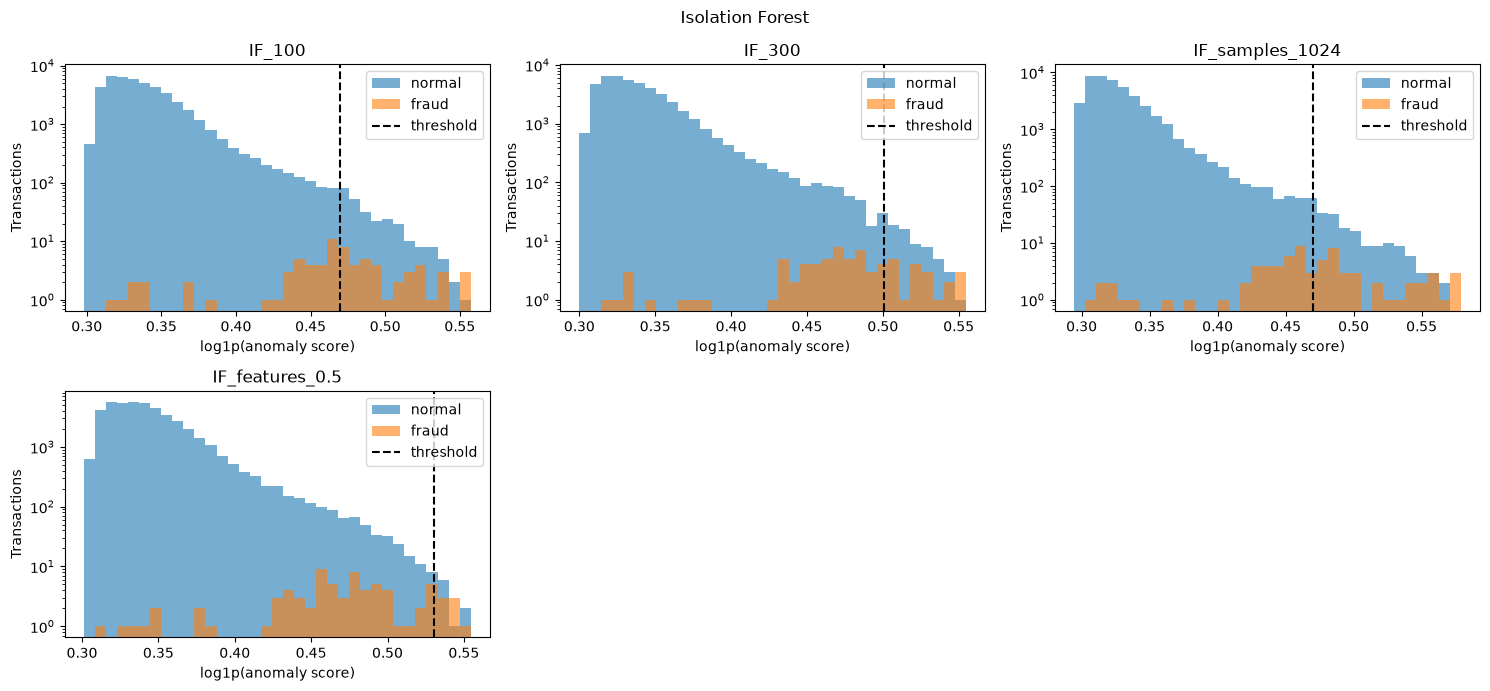

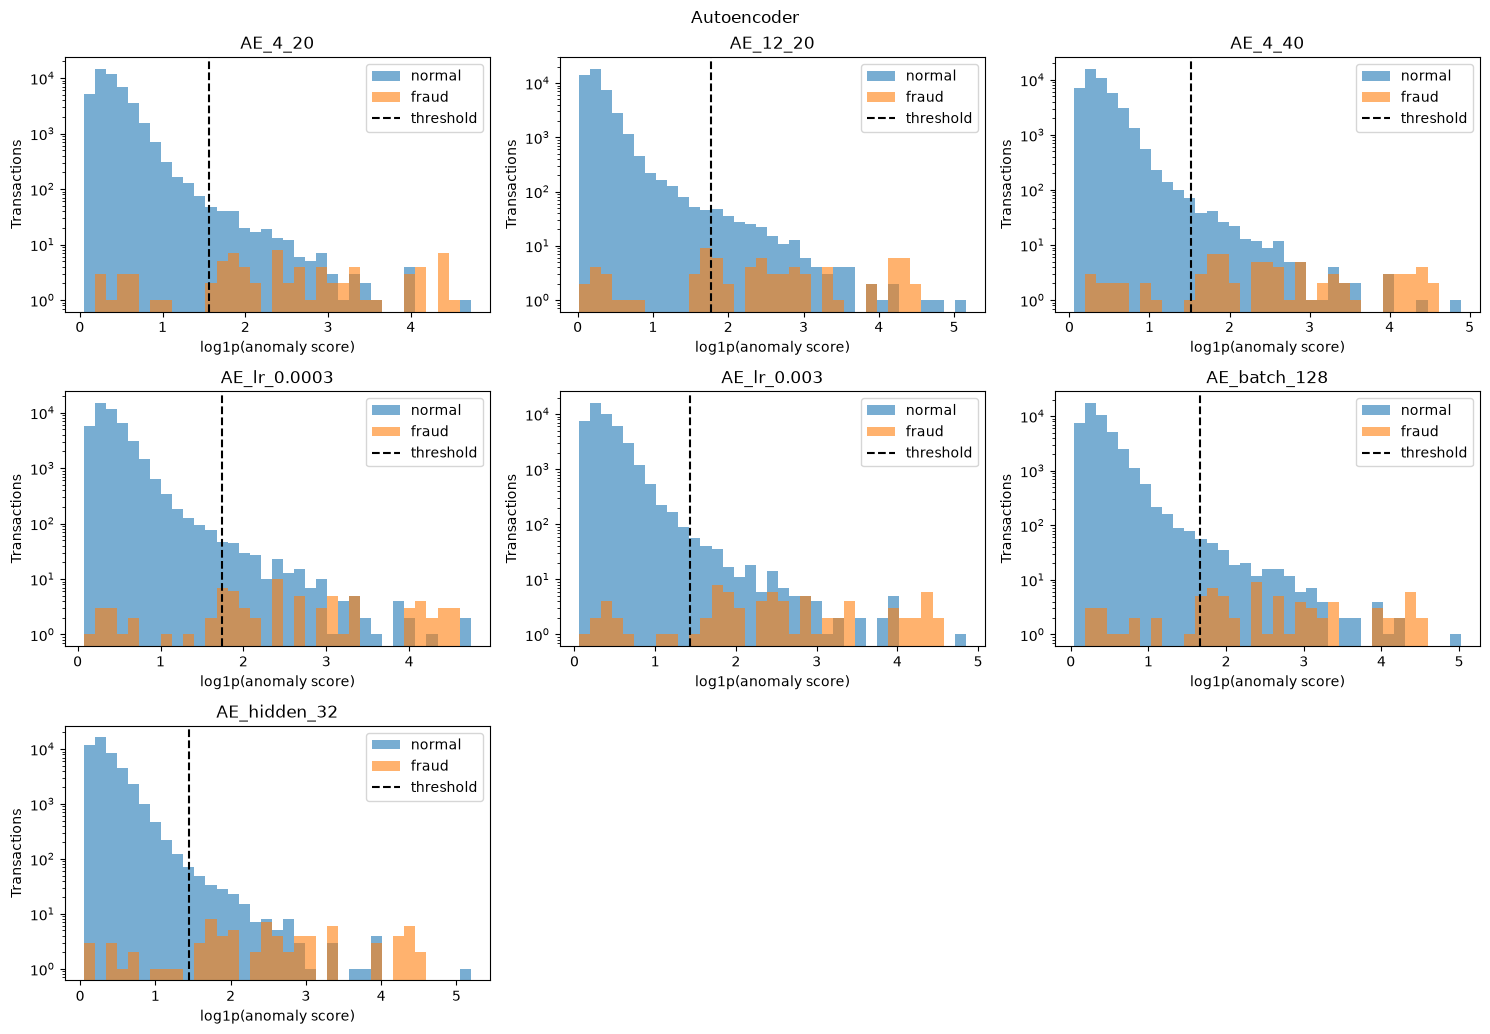

In [15]:
# 모델 종류별로 나누어 모든 실험의 점수 분포를 표시한다.
for family, names in [("Isolation Forest", list(IF_SETTINGS)), ("Autoencoder", list(AE_SETTINGS))]:
    columns = 3
    rows = (len(names) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3.5 * rows), squeeze=False)
    for ax, name in zip(axes.flat, names):
        scores = validation_scores[name]
        plotted_scores = np.log1p(scores)
        bins = np.histogram_bin_edges(plotted_scores, bins=35)
        for label, caption in [(0, "normal"), (1, "fraud")]:
            ax.hist(plotted_scores[y_val == label], bins=bins, alpha=0.6, label=caption)
        threshold = float(
            comparison.loc[comparison["model"] == name, "threshold"].iloc[0]
        )
        ax.axvline(np.log1p(threshold), color="black", linestyle="--", label="threshold")
        ax.set(title=name, xlabel="log1p(anomaly score)", ylabel="Transactions", yscale="log")
        ax.legend()
    for ax in list(axes.flat)[len(names):]:
        ax.set_visible(False)
    fig.suptitle(family)
    plt.tight_layout()
    plt.show()


### 모델과 임계값 선택

검증 F1이 가장 높은 모델·임계값 조합을 선택한다. 모델 간 동점이면 FP가 적고 모델 이름이 앞선 후보를 고른다.
선택한 모델의 임계값별 FP·FN·이상거래 예측 건수를 함께 비교한다. 임계값 선택에는 사기를 놓치는 경우와 정상 거래를 검토하는 부담이 함께 반영된다.


In [16]:
choice = comparison.iloc[0]
selected_name = str(choice["model"])
selected_model = models[selected_name]
selected_threshold = float(choice["threshold"])
selected_scores = validation_scores[selected_name]
print("선택한 모델:", selected_name)
print(f"선택한 임계값: {selected_threshold:.6f}")

display(
    all_results.loc[all_results["model"] == selected_name, metric_columns]
    .sort_values("threshold")
    .round(4)
)


선택한 모델: AE_4_40
선택한 임계값: 3.587428


,model,threshold,AP,precision,recall,f1,TP,FP,FN,predicted_count
30,AE_4_40,1.1611,0.4487,0.0287,0.8816,0.0556,67,2266,9,2333
31,AE_4_40,2.3431,0.4487,0.1236,0.8421,0.2155,64,454,12,518
32,AE_4_40,3.5874,0.4487,0.2199,0.8421,0.3488,64,227,12,291


### 선택 결과 해석

`AE_4_40`, `AE_hidden_32`, `AE_lr_0.003`은 검증 F1 약 0.3488과 오탐 227건으로 동률이다. 정해 둔 동점 처리 기준에 따라 모델 이름이 앞선 `AE_4_40`을 선택했다.
동률인 세 설정의 AP는 각각 약 0.4487·0.4915·0.4664다. 점수 순위 전반의 평가와 특정 임계값에서의 예측 결과를 함께 확인할 수 있다.

선택한 임계값 약 3.5874는 정상 검증 점수의 99.5% 분위수다. 사기 76건 중 64건을 탐지하고 12건을 놓쳤다. 정상 거래 227건을 이상거래로 예측해 전체 예측 건수는 291건이다.

임계값 약 2.3431에서는 같은 사기 64건을 탐지하지만 오탐이 454건이다. 약 1.1611로 더 낮추면 사기 3건을 추가로 찾고 오탐은 2,266건으로 늘어난다. 이 후보들에서는 3.5874가 정밀도와 재현율을 함께 반영한 F1이 가장 높다.

점수 분포에서 임계값 오른쪽의 정상 거래는 오탐, 왼쪽의 사기 거래는 미탐이다. 정상·사기 점수가 겹치는 구간이 있어 임계값을 조절하면 탐지한 사기 수와 오탐 수가 함께 달라진다.

실제 운영에서 검토량이나 사기를 놓쳤을 때의 비용에 별도 조건이 있다면 그 조건에 맞춰 검증 단계의 선택 기준을 정한다.


### 최종 테스트

선택한 모델과 임계값을 고정해 테스트 거래를 평가한다.
검증과 테스트의 사기 수가 적어 일부 거래의 구성 차이도 평가 지표에 영향을 줄 수 있다.


In [ ]:
if selected_name.startswith("IF_"):
    test_scores = -selected_model.score_samples(test_features)
else:
    _, test_scores = reconstruction_scores(selected_model, X_ae_test)

test_metrics = detection_metrics(y_test, test_scores, selected_threshold)
validation_metrics = detection_metrics(y_val, selected_scores, selected_threshold)
display(pd.DataFrame([
    {"split": "validation", "fraud": int(y_val.sum()), **validation_metrics},
    {"split": "test", "fraud": int(y_test.sum()), **test_metrics},
]).round(4))
print(f"사기 {y_test.sum()}건 중 {test_metrics['TP']}건 탐지, {test_metrics['FN']}건 미탐")
print(f"이상거래로 예측한 {test_metrics['predicted_count']}건 중 정상 거래 {test_metrics['FP']}건")


,split,fraud,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
0,validation,76,0.4487,0.9524,0.2199,0.8421,0.3488,64,227,12,291
1,test,95,0.3400,0.9243,0.2040,0.7579,0.3214,72,281,23,353


사기 95건 중 72건 탐지, 23건 미탐
이상거래로 예측한 353건 중 정상 거래 281건


### 테스트 결과 해석

선택한 `AE_4_40`은 테스트 사기 95건 중 72건을 탐지하고 23건을 놓쳤다. 이상거래로 예측한 353건 중 281건이 정상 거래이며, 정밀도는 약 20.4%, 재현율은 약 75.8%다.
검증 F1은 약 0.349, 테스트 F1은 약 0.321이다. 사기 탐지율과 함께 정상 거래를 검토하는 부담도 고려해야 한다.

각 실험은 기준 설정에서 한 항목씩 바꾼 비교다. 여러 설정을 함께 바꾼 조합은 별도로 평가해야 한다.
결과는 지정한 데이터 분할·후보 설정·임계값 범위에서의 비교다.
무작위로 나눈 이틀간의 거래에 대한 평가이며, 이후 기간의 거래를 적용 대상으로 삼으려면 그 기간의 성능을 별도로 확인해야 한다.
